# F26: Tidsavhengige problemer med endelig volum-metoden

Denne notatboken hører til **F26** og kompendiets §3.7 (eksempelet «Avkjøling av en plate»). Den bygger på **F23--F25** og på eksplisitt Euler for varmeligningen fra **F21**.

Vi ser på tidsavhengig varmeledning,
$$
\rho c\,\frac{\partial T}{\partial t} = \frac{\partial}{\partial x}\left(k\frac{\partial T}{\partial x}\right) + S .
$$
Integrerer vi over et kontrollvolum og over tidsintervallet $[t_n, t_{n+1}]$, og evaluerer fluksene ved det *kjente* tidsnivået $t_n$, får vi det **eksplisitte** skjemaet
$$
a_P^0\,T_P^{n+1} = a_W T_W^n + a_E T_E^n + \big(a_P^0 - a_W - a_E + S_P\big)T_P^n + S^u, \qquad a_P^0 = \frac{\rho c\,A\,\delta x}{\Delta t}.
$$

**På matriseform** er dette svært enkelt. Matrisen `L` og høyresiden `F` er *nøyaktig de samme* som i det stasjonære problemet (F23/F24): `L` har $a_P = a_W + a_E - S_P$ på diagonalen og $-a_W$, $-a_E$ utenfor, og `F` inneholder $S^u$. Da kan skjemaet skrives
$$
\rho c\,A\,\delta x\,\frac{T^{n+1} - T^n}{\Delta t} = F - L\,T^n
\qquad\Longrightarrow\qquad
T^{n+1} = T^n + \frac{\Delta t}{\rho c\,A\,\delta x}\big(F - L\,T^n\big).
$$
Det er samme oppbygning som i øvingen om varmeligningen: `u[1:-1, i+1] = u[1:-1, i] + dt*(L @ u[1:-1, i] - F)`. (Der hadde `L` motsatt fortegn, fordi den kom fra $u_{xx}$.)

In [1]:
import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt

## 1. Eksempelet fra kompendiet: avkjøling av en plate

En tynn plate med tykkelse $R = 2$ cm har $k = 10$ W/(m K) og $\rho c = 10\cdot 10^6$ J/(m$^3$ K). Platen har først temperaturen $200\,^\circ$C. Ved $t=0$ settes østsiden ($x = R$) til $0\,^\circ$C, mens vestsiden ($x = 0$) er isolert. Vi regner per flateenhet, $A = 1$ m$^2$.

Den analytiske løsningen er en Fourier-rekke:
$$
T(x,t) = \frac{4T_0}{\pi}\sum_{n=1}^{\infty}\frac{(-1)^{n+1}}{2n-1}\,e^{-\alpha\lambda_n^2 t}\cos(\lambda_n x), \qquad \lambda_n = \frac{(2n-1)\pi}{2R}, \quad \alpha = \frac{k}{\rho c}.
$$

Vi bygger `L` og `F` som i F24: kjent temperatur til høyre, isolert (kjent fluks $q_B = 0$) til venstre.

In [2]:
R = 0.02          # tykkelse [m]
k = 10.0          # varmeledningsevne [W/(m K)]
rho_c = 10e6      # tetthet * spesifikk varmekapasitet [J/(m^3 K)]
A = 1.0
kA = k * A
T0 = 200.0        # starttemperatur
b = 0.0           # temperaturen på østsiden for t > 0

def T_eksakt(x, t, ledd=200):
    alpha = k / rho_c
    s = 0
    for nn in range(1, ledd + 1):
        lam = (2 * nn - 1) * np.pi / (2 * R)
        s += (-1)**(nn + 1) / (2 * nn - 1) * np.exp(-alpha * lam**2 * t) * np.cos(lam * x)
    return 4 * T0 / np.pi * s

# Rutenettgenerering
m = 5
deltax = R / m
x = np.zeros(m + 2)
x[1:-1] = deltax / 2 + deltax * np.arange(m)
x[-1] = R
dx = x[1:] - x[:-1]

# Diskretisering -- akkurat som i det stasjonære tilfellet
koeff_diag  = kA * (1 / dx[:-1] + 1 / dx[1:])
koeff_over  = -kA / dx[1:-1]
koeff_under = -kA / dx[1:-1]
F = np.zeros(m)

koeff_diag[0] -= kA / dx[0]      # vest: isolert (kjent fluks q_B = 0, ingen kobling)
F[-1] += kA / dx[-1] * b         # øst: kjent temperatur

L = np.diag(koeff_over, 1) + np.diag(koeff_under, -1) + np.diag(koeff_diag, 0)
print("L =\n", L)

L =
 [[ 2500. -2500.     0.     0.     0.]
 [-2500.  5000. -2500.     0.     0.]
 [    0. -2500.  5000. -2500.     0.]
 [    0.     0. -2500.  5000. -2500.]
 [    0.     0.     0. -2500.  7500.]]


Nå marsjerer vi i tid med $\Delta t = 2$ s, som i kompendiet. Vi lagrer løsningen i alle tidssteg i en matrise `u[node, tidssteg]`, som i øvingen.

In [3]:
dt = 2.0
tslutt = 120.0
N = int(round(tslutt / dt))           # antall tidssteg
t = np.linspace(0, tslutt, N + 1)

u = np.zeros((m, N + 1))
u[:, 0] = T0                           # initialverdi

for i in range(N):
    u[:, i + 1] = u[:, i] + dt / (rho_c * A * deltax) * (F - L @ u[:, i])

np.set_printoptions(precision=1, suppress=True)
for tt in [40, 80, 120]:
    i = int(round(tt / dt))
    print(f"t = {tt:3d} s:  numerisk {u[:, i]}")
    print(f"           eksakt   {T_eksakt(x[1:-1], tt)}")

t =  40 s:  numerisk [188.6 176.4 148.3 100.8  35.9]
           eksakt   [188.4 175.8 147.1  99.5  35.4]
t =  80 s:  numerisk [153.3 139.1 111.3  72.1  25. ]
           eksakt   [152.7 138.4 110.6  71.6  24.8]
t = 120 s:  numerisk [120.5 108.8  86.5  55.6  19.2]
           eksakt   [119.9 108.2  86.   55.3  19.1]


Tallene er de samme som i tabellen i kompendiet. Vi tegner profilene sammen med den analytiske løsningen. Randverdiene tar vi med som i F23: til høyre er $T = 0$; til venstre er randen isolert, så der bruker vi bare verdien i node 1 for å tegne (temperaturprofilen er flat inn mot randen).

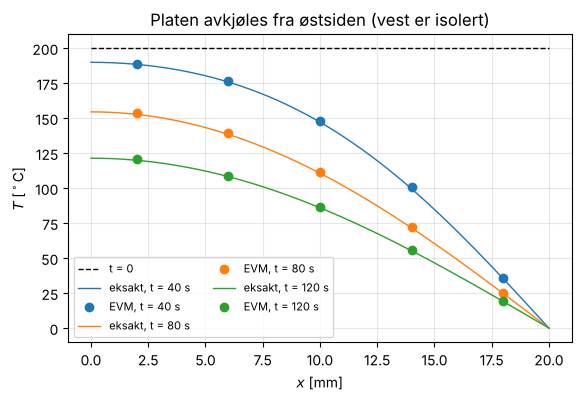

In [4]:
xx = np.linspace(0, R, 300)
plt.figure(figsize=(6.5, 4))
plt.plot([0, R * 1000], [T0, T0], "k--", lw=1, label="t = 0")
for tt, farge in zip([40, 80, 120], ["C0", "C1", "C2"]):
    i = int(round(tt / dt))
    plt.plot(xx * 1000, T_eksakt(xx, tt), "-", color=farge, lw=1, label=f"eksakt, t = {tt:.0f} s")
    plt.plot(x[1:-1] * 1000, u[:, i], "o", color=farge, label=f"EVM, t = {tt:.0f} s")
plt.xlabel("$x$ [mm]"); plt.ylabel(r"$T$ [$^\circ$C]")
plt.legend(fontsize=8, ncol=2); plt.grid(alpha=0.3)
plt.title("Platen avkjøles fra østsiden (vest er isolert)")
plt.show()

## 2. Stabilitet: hvor stort kan $\Delta t$ være?

Koeffisienten foran $T_P^n$ må være positiv: $a_P^0 \ge a_W + a_E - S_P$. Høyresiden er nettopp **diagonalelementet i `L`**! Kravet i hver celle er derfor
$$
\Delta t \le \frac{\rho c\,A\,\delta x}{L_{PP}} .
$$

In [5]:
dt_maks = rho_c * A * deltax / np.diag(L)
print("Største Delta t per celle:", dt_maks)
print("Strengeste krav:          ", dt_maks.min(), "s")

Største Delta t per celle: [16.   8.   8.   8.   5.3]
Strengeste krav:           5.333333333333332 s


* **Celle 1** (isolert): $a_P = a_E$, så $\Delta t \le 16$ s.
* **Celle 2--4** (indre): $a_P = a_W + a_E$, så $\Delta t \le 8$ s -- det samme som $r \le \frac12$ fra F21.
* **Celle 5** (kjent temperatur, avstand $\delta x/2$ til randen): $a_P = a_W - S_P = 3kA/\delta x$, så $\Delta t \le 5.33$ s.

Vi prøver tre tidssteg: $\Delta t = 5$ s (alle krav oppfylt), $\Delta t = 7$ s (bare kravet i randcellen er brutt) og $\Delta t = 9$ s (også kravet i de indre cellene er brutt), og følger temperaturen i **celle 5**, ved den kalde randen.

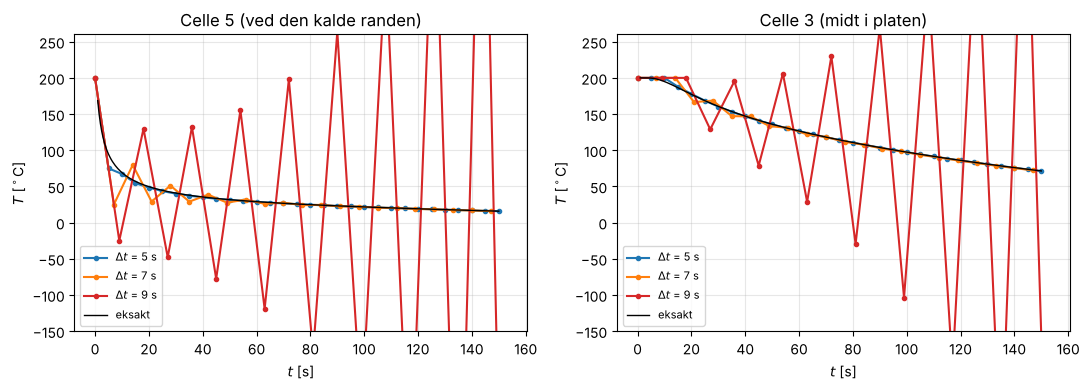

dt = 5 s:  celle 5 de første stegene: [75.  67.2 54.5 48.4 43.5],   etter 400 s: [21.  19.  15.1  9.7  3.3]
dt = 7 s:  celle 5 de første stegene: [25.  79.7 29.1 51.2 29. ],   etter 399 s: [20.8 18.8 14.9  9.6  3.3]
dt = 9 s:  celle 5 de første stegene: [-25.  129.7 -47.9 132.  -77.6],   etter 396 s: [ 16052.5 -46506.8  72480.4 -91302.1 101223.2]


In [6]:
def eksplisitt(dt, tslutt, u0):
    N = int(round(tslutt / dt))
    u = np.zeros((m, N + 1)); u[:, 0] = u0
    for i in range(N):
        u[:, i + 1] = u[:, i] + dt / (rho_c * A * deltax) * (F - L @ u[:, i])
    return np.linspace(0, N * dt, N + 1), u

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tt = np.linspace(1, 150, 300)
for dt_test, farge in [(5, "C0"), (7, "C1"), (9, "C3")]:
    tv, uv = eksplisitt(dt_test, 150, T0)
    ax[0].plot(tv, uv[-1], "o-", ms=3, color=farge, label=rf"$\Delta t$ = {dt_test} s")
    ax[1].plot(tv, uv[2], "o-", ms=3, color=farge, label=rf"$\Delta t$ = {dt_test} s")
ax[0].plot(tt, T_eksakt(x[-2], tt), "k-", lw=1, label="eksakt")
ax[1].plot(tt, T_eksakt(x[3], tt), "k-", lw=1, label="eksakt")
ax[0].set_title("Celle 5 (ved den kalde randen)"); ax[1].set_title("Celle 3 (midt i platen)")
for a in ax:
    a.set_xlabel("$t$ [s]"); a.set_ylabel(r"$T$ [$^\circ$C]"); a.set_ylim(-150, 260)
    a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

for dt_test in [5, 7, 9]:
    tv, uv = eksplisitt(dt_test, 400, T0)
    print(f"dt = {dt_test} s:  celle 5 de første stegene: {uv[-1, 1:6]},   etter {tv[-1]:.0f} s: {uv[:, -1]}")

* **$\Delta t = 5$ s:** Alle koeffisientene er positive, og løsningen oppfører seg fysisk riktig.
* **$\Delta t = 7$ s:** Koeffisienten foran $T_5^n$ er negativ. Temperaturen i celle 5 **hopper opp og ned** ($25$, $80$, $29$, $51\,^\circ$C, ...) -- i en plate som bare avkjøles! Svingningene dempes ut etter hvert, fordi de indre cellene er stabile, men løsningen er fysisk urealistisk i starten.
* **$\Delta t = 9$ s:** Også kravet i de indre cellene er brutt. Nå **vokser** svingningene (sagtannmønsteret fra F21), og løsningen eksploderer.

Velg derfor $\Delta t$ ut fra den *strengeste* cellen, `dt_maks.min()`.

## 3. Fra tidsavhengig til stasjonær løsning

Hva skjer når vi lar tiden gå lenge? Da slutter temperaturen å endre seg, og $T^{n+1} = T^n$. Setter vi det inn i skjemaet, står vi igjen med
$$
F - L\,T = 0 \qquad\Longleftrightarrow\qquad L\,T = F,
$$
som er nøyaktig det **stasjonære** problemet fra F23/F24. Vi sjekker med staven fra F23 ($kA = 10$, $T_V = 100\,^\circ$C, $T_H = 500\,^\circ$C, lengde $0.5$ m), som starter på $20\,^\circ$C. Vi velger $\rho c = 4\cdot 10^6$ J/(m$^3$ K) og $A = 0.01$ m$^2$.

Største tillatte dt: 13.3 s, vi bruker dt = 10.0 s
Etter 3000.0 s: [140. 220. 300. 380. 460.]
Stasjonær (la.solve): [140. 220. 300. 380. 460.]


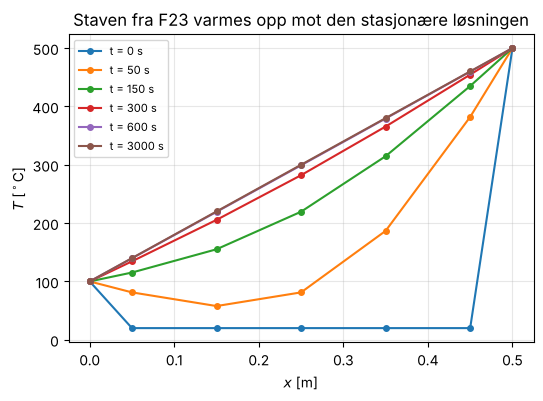

In [7]:
R3, kA3, A3, rho_c3 = 0.5, 10.0, 0.01, 4e6
a3, b3 = 100.0, 500.0
m3 = 5
deltax3 = R3 / m3
x3 = np.zeros(m3 + 2); x3[1:-1] = deltax3 / 2 + deltax3 * np.arange(m3); x3[-1] = R3
dx3 = x3[1:] - x3[:-1]

koeff_diag3  = kA3 * (1 / dx3[:-1] + 1 / dx3[1:])
koeff_over3  = -kA3 / dx3[1:-1]
koeff_under3 = -kA3 / dx3[1:-1]
L3 = np.diag(koeff_over3, 1) + np.diag(koeff_under3, -1) + np.diag(koeff_diag3, 0)
F3 = np.zeros(m3)
F3[0]  += kA3 / dx3[0] * a3
F3[-1] += kA3 / dx3[-1] * b3

dt_maks3 = (rho_c3 * A3 * deltax3 / np.diag(L3)).min()
dt3 = 10.0
print(f"Største tillatte dt: {dt_maks3:.1f} s, vi bruker dt = {dt3} s")

N3 = 300
u3 = np.zeros((m3, N3 + 1)); u3[:, 0] = 20.0
for i in range(N3):
    u3[:, i + 1] = u3[:, i] + dt3 / (rho_c3 * A3 * deltax3) * (F3 - L3 @ u3[:, i])

print("Etter", N3 * dt3, "s:", u3[:, -1])
print("Stasjonær (la.solve):", la.solve(L3, F3))

plt.figure(figsize=(6, 4))
for i in [0, 5, 15, 30, 60, 300]:
    plt.plot(x3, np.r_[a3, u3[:, i], b3], "o-", ms=4, label=f"t = {i * dt3:.0f} s")
plt.xlabel("$x$ [m]"); plt.ylabel(r"$T$ [$^\circ$C]"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.title("Staven fra F23 varmes opp mot den stasjonære løsningen")
plt.show()

Etter lang tid er løsningen den samme som i F23: $140, 220, 300, 380, 460$.

## 4. Tidsavhengig i 2D

I 2D er alt det samme: vi bygger `L` og `F` med `evm_2d` fra F25 (koden er kopiert inn under), og marsjerer med
$$
T^{n+1} = T^n + \frac{\Delta t}{\rho c\,\delta x\,\delta y\,t}\big(F - L\,T^n\big).
$$
Vi bruker platen fra F25 (varmefluks inn fra vest, isolert i sør og øst, $100\,^\circ$C i nord), med $\rho c = 10^6$ J/(m$^3$ K), og lar den starte på $100\,^\circ$C overalt.

In [8]:
def evm_2d(Lx, Ly, m, n, k, t, rand, q=0.0):
    """Fra F25: bygger L og F for  div(k grad T) + q = 0  på en plate med tykkelse t."""
    deltax = Lx / m
    x = np.zeros(m + 2); x[1:-1] = deltax / 2 + deltax * np.arange(m); x[-1] = Lx
    deltay = Ly / n
    y = np.zeros(n + 2); y[1:-1] = deltay / 2 + deltay * np.arange(n); y[-1] = Ly
    Ax, Ay = deltay * t, deltax * t
    L = np.zeros((m * n, m * n)); F = np.zeros(m * n)
    for j in range(n):
        for i in range(m):
            p = j * m + i
            Su = q * deltax * deltay * t; SP = 0.0
            sider = [("V", i > 0,     p - 1, Ax, deltax, y[j + 1]),
                     ("H", i < m - 1, p + 1, Ax, deltax, y[j + 1]),
                     ("S", j > 0,     p - m, Ay, deltay, x[i + 1]),
                     ("N", j < n - 1, p + m, Ay, deltay, x[i + 1])]
            for side, nabo, pn, A, d, s in sider:
                if nabo:
                    a = k * A / d; L[p, pn] = -a; L[p, p] += a
                else:
                    typ, verdi = rand[side]
                    if typ == "T":
                        TB = verdi(s) if callable(verdi) else verdi
                        SP -= 2 * k * A / d; Su += 2 * k * A / d * TB
                    elif typ == "fluks":
                        Su += verdi * A
            L[p, p] -= SP; F[p] = Su
    return x, y, L, F

Lx, Ly, k2, t2, rho_c2 = 0.3, 0.4, 1000.0, 0.01, 1e6
m2, n2 = 15, 20
rand = {"V": ("fluks", 500e3), "H": ("fluks", 0.0), "S": ("fluks", 0.0), "N": ("T", 100.0)}
x2, y2, L2, F2 = evm_2d(Lx, Ly, m2, n2, k2, t2, rand)

dV = (Lx / m2) * (Ly / n2) * t2                  # volumet av en celle
dt_maks2 = rho_c2 * dV / np.diag(L2)
print(f"Indre celle: dt <= {rho_c2 * dV / (4 * k2 * t2):.3f} s")
print(f"Strengeste celle: dt <= {dt_maks2.min():.3f} s  (en celle langs nordveggen)")

Indre celle: dt <= 0.100 s
Strengeste celle: dt <= 0.080 s  (en celle langs nordveggen)


Maks avvik fra stasjonær løsning ved t = 300 s: 1.3475114063227807


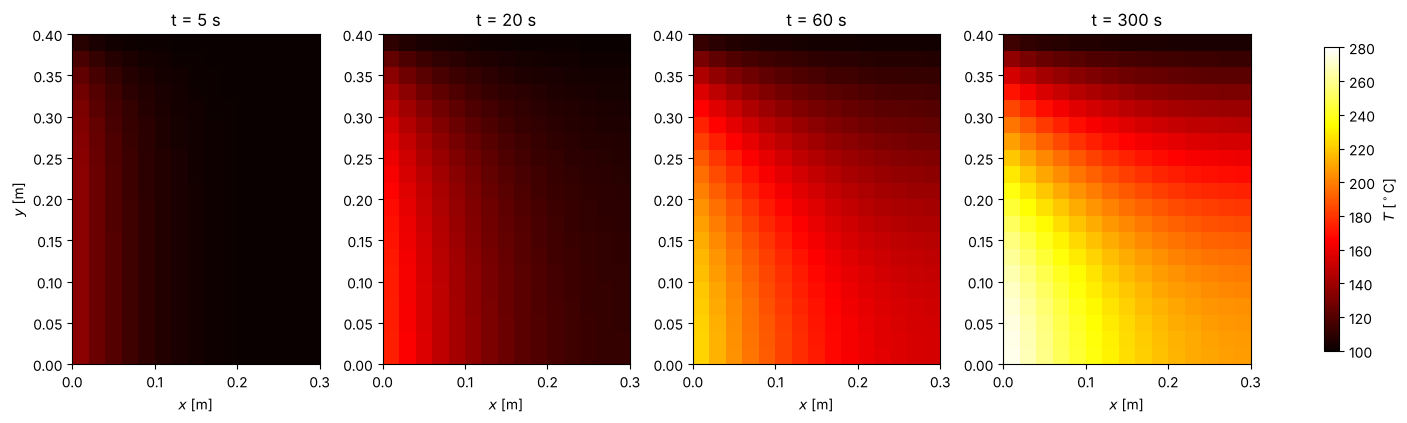

In [9]:
dt2 = 0.06
tider = [5, 20, 60, 300]
u2 = 100.0 * np.ones(m2 * n2)
U_t = {}
tid = 0.0
for i in range(int(round(tider[-1] / dt2))):
    u2 = u2 + dt2 / (rho_c2 * dV) * (F2 - L2 @ u2)
    tid = (i + 1) * dt2
    for tt in tider:
        if abs(tid - tt) < dt2 / 2:
            U_t[tt] = np.reshape(u2, (n2, m2)).copy()

U_stasj = np.reshape(la.solve(L2, F2), (n2, m2))
print("Maks avvik fra stasjonær løsning ved t = 300 s:", np.abs(U_t[300] - U_stasj).max())

fig, ax = plt.subplots(1, 4, figsize=(14, 4.2), constrained_layout=True)
for a, tt in zip(ax, tider):
    im = a.imshow(U_t[tt], origin="lower", extent=[0, Lx, 0, Ly], cmap="hot", vmin=100, vmax=280)
    a.set_title(f"t = {tt} s"); a.set_xlabel("$x$ [m]")
ax[0].set_ylabel("$y$ [m]")
fig.colorbar(im, ax=ax, label=r"$T$ [$^\circ$C]", shrink=0.8)
plt.show()

Varmen trenger inn fra vestveggen og fordeler seg gradvis utover platen. Etter 300 s er vi innenfor om lag $1\,^\circ$C fra den stasjonære løsningen fra F25 (med det samme gitteret).

**Stabilitet i 2D:** For en indre celle er kravet $\Delta t \le \rho c\,h^2/(4k)$, som svarer til $r \le \frac14$ fra F21. Cellene langs nordveggen (kjent temperatur, avstand $h/2$) har $a_P = 3 + 2 = 5$ ganger $kt$, og gir et strengere krav, $\Delta t \le \rho c\,h^2/(5k)$.

## 5. Til orientering: et implisitt skjema

Evaluerer vi fluksene ved det **nye** tidsnivået $t_{n+1}$ i stedet, får vi
$$
\rho c\,A\,\delta x\,\frac{T^{n+1} - T^n}{\Delta t} = F - L\,T^{n+1}
\qquad\Longrightarrow\qquad
\Big(\frac{\rho c\,A\,\delta x}{\Delta t}\,I + L\Big)\,T^{n+1} = \frac{\rho c\,A\,\delta x}{\Delta t}\,T^n + F .
$$
Nå må vi løse et ligningssystem i hvert tidssteg, men til gjengjeld er skjemaet stabilt for **alle** $\Delta t$. Vi prøver på platen fra avsnitt 1 med $\Delta t = 20$ s -- langt over grensen for det eksplisitte skjemaet.

In [10]:
dt_imp = 20.0
M = rho_c * A * deltax / dt_imp
N_imp = int(round(120 / dt_imp))
u_imp = T0 * np.ones(m)
for i in range(N_imp):
    u_imp = la.solve(M * np.eye(m) + L, M * u_imp + F)

print("Implisitt, dt = 20 s, t = 120 s:", u_imp)
print("Eksplisitt, dt = 2 s, t = 120 s:", u[:, -1])
print("Eksakt,               t = 120 s:", T_eksakt(x[1:-1], 120))

Implisitt, dt = 20 s, t = 120 s: [125.2 113.8  91.3  59.3  20.6]
Eksplisitt, dt = 2 s, t = 120 s: [120.5 108.8  86.5  55.6  19.2]
Eksakt,               t = 120 s: [119.9 108.2  86.   55.3  19.1]


Det implisitte skjemaet er stabilt, men med så store tidssteg er det mindre nøyaktig. Stabilitet og nøyaktighet er to forskjellige ting.

## Prøv selv

1. **Finere gitter.** Bruk $m = 20$ kontrollvolum i avsnitt 1. Hva blir `dt_maks.min()` nå? Hvor mange tidssteg trenger du for å komme til $t = 120$ s? (Tidssteget må skaleres som $\delta x^2$.)
2. **Varmekilde.** Gi staven i avsnitt 3 en jevn varmeproduksjon $q$ som i F24 (legg $qA\delta x$ til i `F3`). Hva blir den stasjonære løsningen nå, og stemmer den med `la.solve(L3, F3)`?
3. **Stabilitetsgrensen i 2D.** Kjør 2D-eksempelet med `dt2` litt over og litt under `dt_maks2.min()`, og litt over $\rho c h^2/(4k)$. Hvor i platen dukker svingningene opp først?